# Coach presser embeddings: PCA against the game statistics

A sample of head-coach postgame pressers (YouTube automatic captions, 2023-24
to 2025-26) embedded with Qwen3-Embedding-8B in three views:

| view | text | instruction |
| --- | --- | --- |
| `raw` | the captions as they are | none |
| `instructed` | the captions as they are | basketball instruction |
| `target_view` | coach's team → `Target Team`, the other → `Opponent Team`, player notes | the same instruction, with the labels |

`raw` → `instructed` shows what the instruction does; `instructed` →
`target_view` shows what the rewrite does. The vectors come from
`run_embeddings.py`; this notebook only reads them (no API, no database).

Everything here is the **same game**: the presser is given after the game the
statistics describe. It says what the vectors contain, not whether they help
predict the next game.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from lab.coach_pressers.embedding_analysis import analysis as A
from lab.coach_pressers.embedding_analysis.labels import LABEL_GROUPS

pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 90)

# One colour per view, the same in every chart.
VIEW_COLORS = {"raw": "#2a78d6", "instructed": "#eb6834", "target_view": "#1baf7a"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
DIVERGING = LinearSegmentedColormap.from_list("blue_orange", ["#1c5cab", "#f0efec", "#c2410c"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9, "legend.frameon": False, "figure.dpi": 110,
})

run = A.load_run()
frame, vectors = run.frame, run.vectors
VIEWS = [view for view in VIEW_COLORS if view in vectors]
groups = frame["game_id"].to_numpy()
LABELS = A.label_names()
reduced = {view: A.pca(vectors[view]) for view in VIEWS}
print(f"{len(frame)} pressers, {frame['game_id'].nunique()} games, views: {VIEWS}")

1200 pressers, 798 games, views: ['raw', 'instructed', 'target_view']


## 1. The sample

In [2]:
overview = frame.groupby("season").agg(
    pressers=("presser_id", "size"),
    games=("game_id", "nunique"),
    teams=("team", "nunique"),
    coaches=("coach", "nunique"),
    combined_videos=("combined_video", "mean"),
    words=("n_words", "median"),
    punctuation_per_100_words=("punct_per_100_words", "mean"),
    team_names_replaced=("target_mentions", "mean"),
    opponent_names_replaced=("opponent_mentions", "mean"),
    player_notes=("player_notes", "mean"),
).round(2)
display(overview)
both = frame.groupby("game_id").size().eq(2).sum()
print(f"Games with both coaches in the sample: {both}")
for name, view in run.info.get("views", {}).items():
    print(f"{name}: {view['tokens']:,} tokens, ${view['usd']:.3f}; instruction: {view['instruction']}")

,pressers,games,teams,coaches,combined_videos,words,punctuation_per_100_words,team_names_replaced,opponent_names_replaced,player_notes
season,,,,,,,,,,
2023-24,399,262,27,32,0.18,1147.0,0.17,0.26,0.74,5.03
2024-25,401,247,29,31,0.27,1122.0,4.77,0.20,0.72,5.16
2025-26,400,289,25,29,0.18,1007.0,13.51,0.19,0.60,5.35


Games with both coaches in the sample: 402
raw: 1,553,844 tokens, $0.016; instruction: None
instructed: 1,604,136 tokens, $0.016; instruction: Represent this NBA head coach's postgame press conference: how his team and the opponent played (result, offense, defense, effort, pace) and which players were hurt or unavailable.
target_view: 1,686,773 tokens, $0.017; instruction: Represent this NBA head coach's postgame press conference from the Target Team's point of view: how the Target Team and the Opponent Team played (result, offense, defense, effort, pace) and which players were hurt or unavailable.


A coach almost never names the two teams ("we", "they"): the rewrite replaces
less than one team name per presser. What it adds is the opening sentence
(which side the coach is on) and about five player notes.

One presser, the start of its two texts:

In [3]:
EXAMPLE = 0  # row of the sample
row = frame.iloc[EXAMPLE]
print(f"{row.season}  {row.team} vs {row.opponent}  {row.coach}  margin {row.target_margin:+.0f}\n{row.title}\n")
print("RAW\n" + run.texts["raw"].iloc[EXAMPLE][:700] + " ...\n")
print("TARGET VIEW\n" + run.texts["target_view"].iloc[EXAMPLE][:900] + " ...")

2023-24  LAC vs PHI  Tyronn Lue  margin -14
"They Understand What The F**** They Need To Do!" Ty Lue Reacts To Clippers  121-107 Loss To Sixers

RAW
T I know you said you you always said you want to start games with the defensive mindset you SE by basically scor first three Bas of the game um and then looks like they just were comfortable when that in the floor the whole time what what did you see there why is the defense especially Giving Up So Many comfortable looks from three yeah it started off early you know um no physicality I think we started the game with a physicality um and they got comfortable like you said early in the game you know making threes um Tobias got to his spot a couple times made a three um and then Kelly you know he made a couple threes to kind of get him going with the momentum and so I thought we did a good job ...

TARGET VIEW
In this text, the head coach of the Target Team (home team) answers reporters after the game against the Opponent Team (visiting team

## 2. How far apart are the three views?

Cosine between the vectors of the same presser.

,raw / instructed,raw / target_view,instructed / target_view
mean,0.929,0.846,0.906
std,0.021,0.029,0.022
min,0.834,0.679,0.798
50%,0.930,0.848,0.911
max,0.983,0.923,0.959


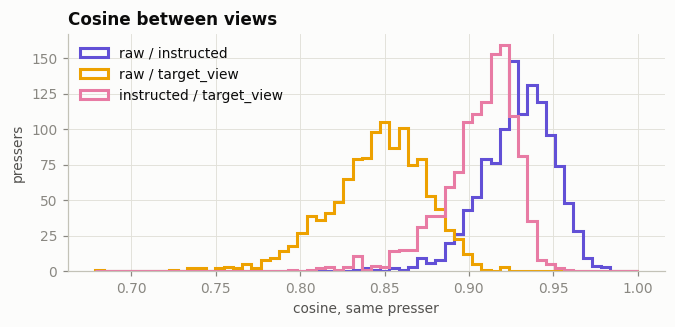

In [4]:
cosines = A.view_cosines({view: vectors[view] for view in VIEWS})
display(cosines.describe().loc[["mean", "std", "min", "50%", "max"]].round(3))

fig, ax = plt.subplots(figsize=(7, 2.8))
pair_colors = ["#6250d6", "#eda100", "#e87ba4"]
bins = np.linspace(cosines.min().min(), 1, 60)
for (pair, values), color in zip(cosines.items(), pair_colors):
    ax.hist(values, bins=bins, histtype="step", linewidth=2, color=color, label=pair)
ax.set(xlabel="cosine, same presser", ylabel="pressers", title="Cosine between views")
ax.legend(loc="upper left")
plt.show()

## 3. PCA spectrum

,PC1,top 10,top 64,top 256,effective dimension
raw,0.062,0.234,0.553,0.849,97.475
instructed,0.060,0.231,0.550,0.844,101.821
target_view,0.062,0.242,0.565,0.854,94.833


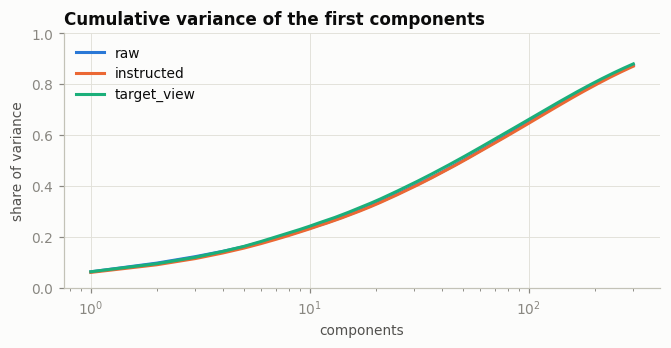

In [5]:
spectrum = pd.DataFrame({
    view: {
        "PC1": r.ratio[0], "top 10": r.ratio[:10].sum(), "top 64": r.ratio[:64].sum(),
        "top 256": r.ratio[:256].sum(), "effective dimension": r.effective_dimension,
    } for view, r in reduced.items()
}).T
display(spectrum.round(3))

fig, ax = plt.subplots(figsize=(7, 3))
for view in VIEWS:
    ax.plot(np.arange(1, 301), reduced[view].ratio[:300].cumsum(), color=VIEW_COLORS[view], linewidth=2, label=view)
ax.set(xscale="log", xlabel="components", ylabel="share of variance", title="Cumulative variance of the first components", ylim=(0, 1))
ax.legend(loc="upper left")
plt.show()

## 4. Components against the statistics

Pearson r of the first components with the transcript's own properties
(length, punctuation, combined video), the season, and the game statistics
seen from the coach's team. Cells with |r| ≥ 0.2 carry the value. With about
1,200 pressers, |r| under 0.06 is noise.

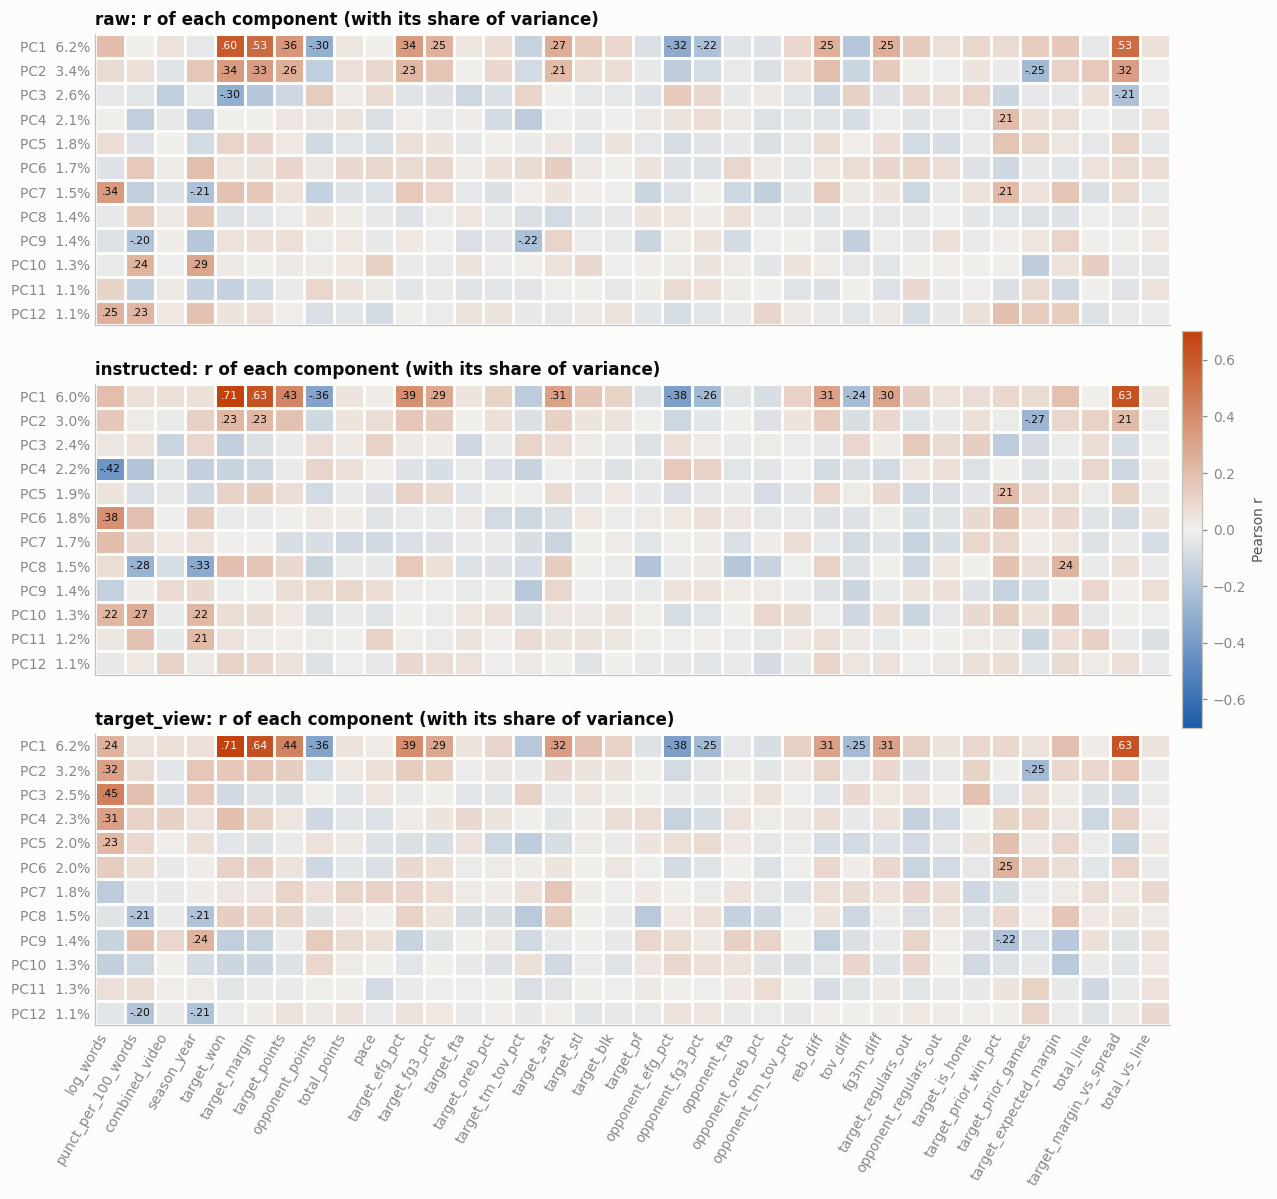

In [6]:
N_COMPONENTS = 12
columns = list(A.NUISANCE) + LABELS
season_year = frame["season"].str[:4].astype(float).rename("season_year")
table_frame = pd.concat([frame[list(A.NUISANCE)], season_year, frame[LABELS]], axis=1)
corr = {view: A.correlations(reduced[view].scores, table_frame, N_COMPONENTS) for view in VIEWS}

fig, axes = plt.subplots(len(VIEWS), 1, figsize=(15, 3.9 * len(VIEWS)), sharex=True)
for ax, view in zip(np.atleast_1d(axes), VIEWS):
    values = corr[view].to_numpy()
    image = ax.imshow(values, cmap=DIVERGING, vmin=-0.7, vmax=0.7, aspect="auto")
    for i, j in zip(*np.where(np.abs(values) >= 0.2)):
        ax.text(j, i, f"{values[i, j]:.2f}".replace("0.", "."), ha="center", va="center",
                fontsize=7, color="white" if abs(values[i, j]) > 0.45 else INK)
    ratio = reduced[view].ratio
    ax.set_yticks(range(N_COMPONENTS), [f"PC{i + 1}  {ratio[i]:.1%}" for i in range(N_COMPONENTS)])
    ax.set_title(f"{view}: r of each component (with its share of variance)")
    ax.grid(False)
    ax.set_xticks(np.arange(-0.5, values.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, N_COMPONENTS), minor=True)
    ax.grid(which="minor", color="#fcfcfb", linewidth=2)
    ax.tick_params(which="both", length=0)
ax.set_xticks(range(len(corr[view].columns)), corr[view].columns, rotation=60, ha="right")
fig.colorbar(image, ax=axes, shrink=0.4, pad=0.01, label="Pearson r")
plt.show()

In [7]:
# The statistic each component follows most, per view.
rows = []
for view in VIEWS:
    for pc, values in corr[view].iterrows():
        best = values.abs().idxmax()
        rows.append({"view": view, "component": pc, "closest": f"{best} ({values[best]:+.2f})"})
display(pd.DataFrame(rows).pivot(index="component", columns="view", values="closest").loc[corr[VIEWS[0]].index, VIEWS])

view,raw,instructed,target_view
PC1,target_won (+0.60),target_won (+0.71),target_won (+0.71)
PC2,target_won (+0.34),target_prior_games (-0.27),log_words (+0.32)
PC3,target_won (-0.30),target_prior_win_pct (-0.17),log_words (+0.45)
PC4,target_prior_win_pct (+0.21),log_words (-0.42),log_words (+0.31)
PC5,target_prior_win_pct (+0.17),target_prior_win_pct (+0.21),log_words (+0.23)
PC6,season_year (+0.19),log_words (+0.38),target_prior_win_pct (+0.25)
PC7,log_words (+0.34),log_words (+0.20),log_words (-0.17)
PC8,season_year (+0.17),season_year (-0.33),punct_per_100_words (-0.21)
PC9,target_tm_tov_pct (-0.22),target_tm_tov_pct (-0.18),season_year (+0.24)
PC10,season_year (+0.29),punct_per_100_words (+0.27),target_expected_margin (-0.17)


## 5. How much of the vectors do the statistics explain?

Ridge from each block of variables to the first 100 component scores, out of
fold (both pressers of a game in the same fold). Blocks are added one after
another. `variance_explained` is the share of the **whole** vector variance
(components after the 100th count as unexplained).

In [8]:
blocks = {
    "transcript (length, punctuation, combined)": A.design(frame, A.NUISANCE),
    "season": A.one_hot(frame["season"]),
    "game statistics": A.design(frame, LABELS),
    "team": A.one_hot(frame["team"]),
    "coach": A.one_hot(frame["coach"]),
    "opponent": A.one_hot(frame["opponent"]),
}
explained = {view: A.explained_by(reduced[view], blocks, groups) for view in VIEWS}
summary = pd.DataFrame({view: table.set_index("features")["variance_explained"] for view, table in explained.items()})
display(summary.round(3))
for view in VIEWS:
    print(view)
    display(explained[view].set_index("features").filter(like="_r2").round(2))

,raw,instructed,target_view
features,,,
"transcript (length, punctuation, combined)",0.011,0.018,0.022
+ season,0.016,0.021,0.025
+ game statistics,0.054,0.065,0.069
+ team,0.094,0.103,0.108
+ coach,0.095,0.104,0.109
+ opponent,0.096,0.108,0.106


raw


,PC1_r2,PC2_r2,PC3_r2,PC4_r2,PC5_r2
features,,,,,
"transcript (length, punctuation, combined)",0.03,0.00,0.02,0.01,0.00
+ season,0.04,0.08,0.01,0.03,0.01
+ game statistics,0.43,0.22,0.14,0.09,0.04
+ team,0.45,0.25,0.20,0.15,0.05
+ coach,0.45,0.25,0.20,0.15,0.04
+ opponent,0.43,0.24,0.18,0.15,0.04


instructed


,PC1_r2,PC2_r2,PC3_r2,PC4_r2,PC5_r2
features,,,,,
"transcript (length, punctuation, combined)",0.04,0.02,0.01,0.22,0.00
+ season,0.04,0.10,0.02,0.22,0.01
+ game statistics,0.58,0.15,0.12,0.24,0.06
+ team,0.59,0.20,0.15,0.28,0.08
+ coach,0.59,0.20,0.15,0.28,0.08
+ opponent,0.57,0.18,0.14,0.27,0.08


target_view


,PC1_r2,PC2_r2,PC3_r2,PC4_r2,PC5_r2
features,,,,,
"transcript (length, punctuation, combined)",0.06,0.10,0.24,0.12,0.05
+ season,0.06,0.18,0.24,0.12,0.05
+ game statistics,0.59,0.20,0.32,0.15,0.12
+ team,0.60,0.26,0.33,0.20,0.14
+ coach,0.59,0.25,0.33,0.20,0.15
+ opponent,0.58,0.23,0.31,0.19,0.13


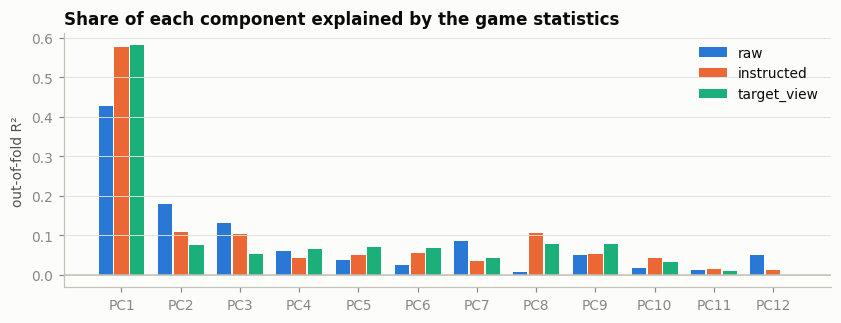

In [9]:
# R2 of each component from the game statistics alone, and from everything.
stats_only = {view: A.component_r2(reduced[view], A.design(frame, LABELS), groups, N_COMPONENTS) for view in VIEWS}
fig, ax = plt.subplots(figsize=(9, 3))
width = 0.8 / len(VIEWS)
for index, view in enumerate(VIEWS):
    x = np.arange(N_COMPONENTS) + (index - (len(VIEWS) - 1) / 2) * width
    ax.bar(x, stats_only[view], width=width * 0.9, color=VIEW_COLORS[view], label=view)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_xticks(range(N_COMPONENTS), [f"PC{i + 1}" for i in range(N_COMPONENTS)])
ax.set(ylabel="out-of-fold R²", title="Share of each component explained by the game statistics")
ax.grid(axis="x", visible=False)
ax.legend()
plt.show()

## 6. What can be read from the full vectors?

The reverse direction: a ridge probe from the whole vector (4,096 dimensions)
to each statistic, out of fold. Bars are Pearson r between the prediction and
the truth, with a 95% interval. One sample and one fold split: differences
between views inside the intervals are not differences.

,group,raw,instructed,target_view
label,,,,
target_won,result,0.827,0.839,0.840
target_margin,result,0.722,0.730,0.732
target_points,result,0.506,0.519,0.540
opponent_points,result,0.451,0.483,0.488
total_points,result,0.242,0.286,0.317
pace,result,0.278,0.303,0.274
target_efg_pct,target_box,0.499,0.497,0.505
target_fg3_pct,target_box,0.318,0.333,0.348
target_fta,target_box,0.148,0.154,0.109


AUC of the binary labels


,raw,instructed,target_view
label,,,
target_won,0.975,0.978,0.980
target_is_home,0.685,0.695,0.966


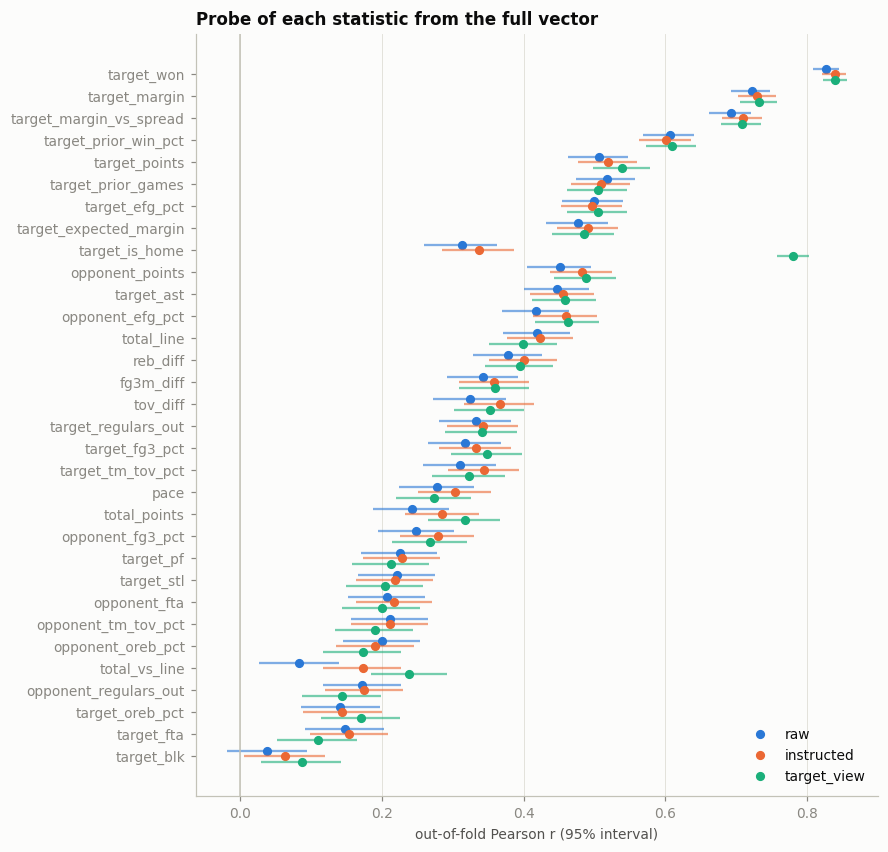

In [10]:
probes = {view: A.probe(vectors[view], frame, LABELS) for view in VIEWS}
r_table = pd.DataFrame({view: table.set_index("label")["r"] for view, table in probes.items()})
group_of = {name: group for group, names in LABEL_GROUPS.items() for name in names}
r_table.insert(0, "group", r_table.index.map(group_of))
display(r_table.round(3))
auc = pd.DataFrame({view: table.set_index("label")["auc"].dropna() for view, table in probes.items()})
print("AUC of the binary labels"); display(auc.round(3))

order = r_table[VIEWS].mean(1).sort_values().index
fig, ax = plt.subplots(figsize=(8, 9))
offsets = np.linspace(0.25, -0.25, len(VIEWS))
for offset, view in zip(offsets, VIEWS):
    table = probes[view].set_index("label").loc[order]
    y = np.arange(len(order)) + offset
    ax.hlines(y, table["r_low"], table["r_high"], color=VIEW_COLORS[view], linewidth=1.5, alpha=0.6)
    ax.plot(table["r"], y, "o", markersize=5, color=VIEW_COLORS[view], label=view)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.set(xlabel="out-of-fold Pearson r (95% interval)", title="Probe of each statistic from the full vector")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

## 7. A look at the components

Each view's first two components, coloured by the final margin of the coach's
team, and the pressers at both ends of a component.

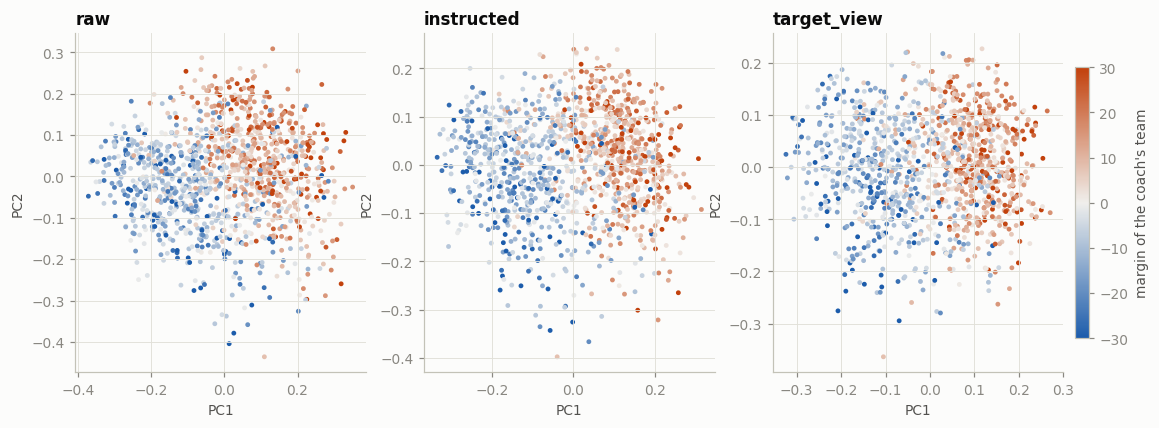

In [11]:
fig, axes = plt.subplots(1, len(VIEWS), figsize=(4.6 * len(VIEWS), 4), sharex=False)
for ax, view in zip(np.atleast_1d(axes), VIEWS):
    scores = reduced[view].scores
    points = ax.scatter(scores[:, 0], scores[:, 1], c=frame["target_margin"], cmap=DIVERGING,
                        vmin=-30, vmax=30, s=10, linewidths=0)
    ax.set(xlabel="PC1", ylabel="PC2", title=view)
fig.colorbar(points, ax=axes, shrink=0.8, pad=0.01, label="margin of the coach's team")
plt.show()

In [12]:
VIEW, COMPONENT = "target_view", 1
display(A.extremes(reduced[VIEW].scores, frame, COMPONENT, n=6))

,end,score,season,team,opponent,coach,target_margin,n_words,title
0,low,-0.324,2025-26,PHI,OKC,Nick Nurse,-25,659,Philadelphia 76ers Postgame Media Availability 🎙️ | Coach Nurse | 12.28.25
1,low,-0.321,2023-24,UTA,POR,Will Hardy,-16,279,Will Hardy Following 16-Turnover Half in Jazz Loss to Blazers: 'That was Ugly'
2,low,-0.312,2025-26,MEM,NOP,Tuomas Iisalo,-6,378,Tuomas Iisalo Press Conference | Grizzlies vs. Pelicans
3,low,-0.309,2025-26,MIN,ORL,Chris Finch,-27,896,"“The Effort Was There, But We Couldn't Hit Shots.” | Chris Finch Post Game Sound | 03...."
4,low,-0.307,2023-24,BOS,IND,Joe Mazzulla,-10,899,Joe Mazzulla Reacts to Buddy Hield Shot vs Celtics: I Don't Care | Postgame Interview ...
5,low,-0.306,2023-24,ATL,MIA,Quin Snyder,-8,772,Hawks vs. Heat Postgame Press Conference: Quin Snyder
6,high,0.270,2025-26,CLE,MEM,Kenny Atkinson,16,542,Cavs at Grizzlies | Kenny Atkinson Post Game | 04.06.2026
7,high,0.264,2024-25,OKC,IND,Mark Daigneault,21,2514,"Full Post Game Media Availability | OKC Thunder vs Indiana Pacers | March 29, 2025"
8,high,0.254,2025-26,DET,BKN,J. B. Bickerstaff,38,630,Post-Game Press Conference: J.B. Bickerstaff | Pistons vs. Nets | 03.10.26
9,high,0.253,2025-26,NOP,DAL,Willie Green,2,765,Willie Green Recaps Win vs. Dallas | Pelicans-Mavericks Postgame 11/5/2025


In [13]:
VIEW, COMPONENT = "target_view", 2
display(A.extremes(reduced[VIEW].scores, frame, COMPONENT, n=6))

,end,score,season,team,opponent,coach,target_margin,n_words,title
0,low,-0.364,2024-25,LAC,DET,Tyronn Lue,8,188,"FULL Clippers Postgame Interviews vs. Pistons: James Harden, Ivica Zubac, Bogdanovic A..."
1,low,-0.295,2024-25,BOS,NYK,Joe Mazzulla,-38,1482,Joe Mazzulla full postgame press conference | Round 2 Game 6 vs. New York Knicks
2,low,-0.280,2025-26,MIL,PHI,Doc Rivers,-20,1293,Doc Rivers Postgame Press Conference | 04.12.26
3,low,-0.277,2024-25,CHA,BOS,Charles Lee,-7,629,Hornets at Celtics: Coach Charles Lee Postgame Media Availability | 4/13/2025
4,low,-0.276,2024-25,SAC,OKC,Doug Christie,-34,395,Coach Christie | Postgame Interview 2.1.25
5,low,-0.263,2023-24,MIA,TOR,Erik Spoelstra,15,872,Postgame Interview: Erik Spoelstra
6,high,0.227,2025-26,HOU,CHA,Ime Udoka,4,1347,Press Conference by Ime Udoka vs Hornets
7,high,0.221,2023-24,BOS,NOP,Joe Mazzulla,12,1962,"Joe Mazzulla on Celtics Bounce Back Win vs Pelicans: ""It's impossible to ignore the no..."
8,high,0.220,2025-26,NOP,MIN,James Borrego,-9,1755,James Borrego | Pelicans-Timberwolves Postgame interview 12/4/25
9,high,0.218,2025-26,WAS,CHA,Brian Keefe,-17,1673,Media Availability: Head Coach Brian Keefe and Jaden Hardy | 2.22.26
